# Семантические признаки музыкальных треков

Небольшой эксперимент с контентными рекомендациями. Я собрал 100 треков, извлёк признаки из 30-секундных фрагментов, добавил настроение и контекст, а затем проверил, насколько такое представление подходит для поиска похожей музыки.

Весь путь — от сбора данных до примеров соседей — находится в этом ноутбуке. Для повторного запуска ключи API не нужны.

<a id="task-1"></a>
## Задание 1. Сбор датасета

Источник — открытый Deezer API. Для каждого трека сохраняются название, исполнитель, альбом, жанр, ссылка на страницу и ссылка на 30-секундный preview.

Я взял по 10 треков из чартов 10 жанров: pop, rap/hip-hop, rock, dance, r&b, alternative, electro, folk, jazz и classical. В итоговой выборке не больше двух треков одного исполнителя. Дубликаты по `track_id` удаляются. Такой отбор даёт ровно 100 треков и не позволяет одному жанру или артисту занять почти весь датасет.

Ограничение отбора: чарты содержат популярную музыку и не представляют весь каталог. Жанр назначен по разделу чарта, поэтому пограничные треки могут подходить сразу нескольким категориям.

In [1]:
!pip install pandas numpy requests librosa scikit-learn matplotlib seaborn umap-learn tqdm -q

'pip' is not recognized as an internal or external command,
operable program or batch file.


In [2]:
import json
import time
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import umap.umap_ as umap
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

случайное_состояние = 42
папка_данных = Path('data')
папка_графиков = Path('results/figures')
папка_данных.mkdir(exist_ok=True)
папка_графиков.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')

In [3]:
жанры = {
    132: 'pop',
    116: 'rap/hip-hop',
    152: 'rock',
    113: 'dance',
    165: 'r&b',
    85: 'alternative',
    106: 'electro',
    466: 'folk',
    129: 'jazz',
    98: 'classical'
}

def запросить_json(адрес, попытки=3):
    for номер_попытки in range(попытки):
        ответ = requests.get(адрес, timeout=30)
        if ответ.ok:
            данные = ответ.json()
            if not данные.get('error'):
                return данные
        time.sleep(1 + номер_попытки)
    raise RuntimeError(f'не удалось получить данные: {адрес}')

def собрать_датасет(на_жанр=10, максимум_на_артиста=2):
    строки = []
    счетчик_артистов = {}
    собранные_id = set()

    for жанр_id, жанр in жанры.items():
        адрес = f'https://api.deezer.com/chart/{жанр_id}/tracks?limit=50'
        кандидаты = запросить_json(адрес)['data']
        добавлено = 0

        for трек in кандидаты:
            исполнитель = трек['artist']['name']
            if трек['id'] in собранные_id:
                continue
            if счетчик_артистов.get(исполнитель, 0) >= максимум_на_артиста:
                continue
            if not трек.get('preview'):
                continue

            подробно = запросить_json(f"https://api.deezer.com/track/{трек['id']}")
            строки.append({
                'track_id': подробно['id'],
                'название': подробно['title'],
                'исполнитель': подробно['artist']['name'],
                'альбом': подробно['album']['title'],
                'жанр': жанр,
                'длительность_сек': подробно['duration'],
                'дата_релиза': подробно.get('release_date'),
                'рейтинг_deezer': подробно.get('rank'),
                'explicit': подробно.get('explicit_lyrics'),
                'track_url': подробно['link'],
                'preview_url': подробно['preview'],
                'источник': 'Deezer API'
            })
            собранные_id.add(трек['id'])
            счетчик_артистов[исполнитель] = счетчик_артистов.get(исполнитель, 0) + 1
            добавлено += 1

            if добавлено == на_жанр:
                break

        if добавлено < на_жанр:
            raise RuntimeError(f'для жанра {жанр} собрано только {добавлено} треков')

    return pd.DataFrame(строки).drop_duplicates('track_id').reset_index(drop=True)

путь_к_исходным = папка_данных / 'music_dataset.csv'
if путь_к_исходным.exists():
    датасет = pd.read_csv(путь_к_исходным)
else:
    датасет = собрать_датасет()
    датасет.to_csv(путь_к_исходным, index=False, encoding='utf-8-sig')

print(f'Треков: {len(датасет)}')
print(f"Исполнителей: {датасет['исполнитель'].nunique()}")
print(f"Максимум треков одного исполнителя: {датасет['исполнитель'].value_counts().max()}")
display(датасет.head())

Треков: 100
Исполнителей: 91
Максимум треков одного исполнителя: 2


,track_id,название,исполнитель,альбом,жанр,длительность_сек,дата_релиза,рейтинг_deezer,explicit,track_url,preview_url,источник
0,4250696681,Nicole Kidman,ADÉLA,PRIMA,pop,181,2026-09-04,990767,True,https://www.deezer.com/track/4250696681,https://cdnt-preview.dzcdn.net/api/1/1/0/8/b/0...,Deezer API
1,4045817471,hate that i made you love me,Ariana Grande,hate that i made you love me,pop,198,2026-05-29,999011,False,https://www.deezer.com/track/4045817471,https://cdnt-preview.dzcdn.net/api/1/1/c/1/0/0...,Deezer API
2,3602074142,Choosin' Texas,Ella Langley,Choosin' Texas,pop,232,2025-10-17,978085,False,https://www.deezer.com/track/3602074142,https://cdnt-preview.dzcdn.net/api/1/1/5/b/5/0...,Deezer API
3,3895241341,Boston,STELLA LEFTY,Boston,pop,170,2026-03-27,873262,False,https://www.deezer.com/track/3895241341,https://cdnt-preview.dzcdn.net/api/1/1/a/d/f/0...,Deezer API
4,4078104881,stupid song,Olivia Rodrigo,you seem pretty sad for a girl so in love,pop,209,2026-06-12,965662,False,https://www.deezer.com/track/4078104881,https://cdnt-preview.dzcdn.net/api/1/1/c/c/f/0...,Deezer API


<a id="task-2"></a>
## Задание 2. Набор признаков

Я выбрал признаки, которые можно получить из самого звука и объяснить без сложной модели:

- `tempo` — оценка темпа
- `rms` — средняя энергия сигнала
- `onset_rate` — плотность атак, примерно отражает ритмическую активность
- `spectral_centroid` и `spectral_bandwidth` — яркость и ширина спектра
- `spectral_rolloff` — частота, ниже которой находится основная энергия спектра
- `zero_crossing_rate` — доля переходов через ноль, полезна для шумности и перкуссивности
- `chroma_std` — изменчивость хроматического профиля
- 13 средних MFCC — компактное описание тембра

На их основе добавляются три интерпретируемых поля: `настроение`, `контекст` и `атмосфера`. Для рекомендаций числовые признаки дают плавную меру похожести, а семантические поля позволяют фильтровать музыку понятными словами. Жанр полезен как грубая категория, но близкие по звучанию треки могут находиться и между жанрами.

<a id="task-3"></a>
## Задание 3. Извлечение признаков

Метаданные берутся из Deezer API, а звук анализируется библиотекой `librosa`. Каждый preview загружается в память и приводится к моно с частотой 22050 Гц. Для устойчивости я усредняю покадровые значения по всему фрагменту.

Семантические метки получаются прозрачными правилами после нормализации признаков. Настроение зависит от энергии, темпа и спектральной яркости. Контекст учитывает энергию, темп и плотность атак. Атмосфера связана с яркостью, тембральной изменчивостью и энергией. Это простая базовая модель: её легко повторить и проверить, но она не понимает текст песни и культурный контекст.

Я рассматривал CLAP и музыкальные трансформеры. Они дают более богатые эмбеддинги, но тяжелее запускаются в Colab и хуже объясняются на выборке из 100 треков. LLM по названию и исполнителю тоже возможна, однако в этом случае метки будут описывать метаданные, а не услышанный фрагмент.

In [4]:
def извлечь_признаки(preview_url):
    ответ = requests.get(preview_url, timeout=60)
    ответ.raise_for_status()
    временный_путь = папка_данных / '_preview.mp3'
    временный_путь.write_bytes(ответ.content)
    сигнал, частота = librosa.load(str(временный_путь), sr=22050, mono=True)
    временный_путь.unlink(missing_ok=True)

    темп, _ = librosa.beat.beat_track(y=сигнал, sr=частота)
    rms = librosa.feature.rms(y=сигнал)
    центроид = librosa.feature.spectral_centroid(y=сигнал, sr=частота)
    ширина = librosa.feature.spectral_bandwidth(y=сигнал, sr=частота)
    rolloff = librosa.feature.spectral_rolloff(y=сигнал, sr=частота)
    переходы = librosa.feature.zero_crossing_rate(сигнал)
    chroma = librosa.feature.chroma_stft(y=сигнал, sr=частота)
    mfcc = librosa.feature.mfcc(y=сигнал, sr=частота, n_mfcc=13)
    атаки = librosa.onset.onset_detect(y=сигнал, sr=частота, units='time')

    признаки = {
        'tempo': float(np.asarray(темп).reshape(-1)[0]),
        'rms': float(rms.mean()),
        'onset_rate': float(len(атаки) / (len(сигнал) / частота)),
        'spectral_centroid': float(центроид.mean()),
        'spectral_bandwidth': float(ширина.mean()),
        'spectral_rolloff': float(rolloff.mean()),
        'zero_crossing_rate': float(переходы.mean()),
        'chroma_std': float(chroma.mean(axis=1).std())
    }
    признаки.update({f'mfcc_{номер + 1}': float(значение) for номер, значение in enumerate(mfcc.mean(axis=1))})
    return признаки

путь_к_признакам = папка_данных / 'audio_features.csv'
if путь_к_признакам.exists():
    аудио_признаки = pd.read_csv(путь_к_признакам)
else:
    строки = []
    for трек in tqdm(датасет.itertuples(), total=len(датасет), desc='признаки'):
        строки.append({'track_id': трек.track_id, **извлечь_признаки(трек.preview_url)})
    аудио_признаки = pd.DataFrame(строки)
    аудио_признаки.to_csv(путь_к_признакам, index=False)

df = датасет.merge(аудио_признаки, on='track_id', validate='one_to_one')
print(f'Размер после объединения: {df.shape}')

Размер после объединения: (100, 33)


In [5]:
базовые_признаки = [
    'tempo', 'rms', 'onset_rate', 'spectral_centroid',
    'spectral_bandwidth', 'spectral_rolloff',
    'zero_crossing_rate', 'chroma_std'
]

нормализованные = pd.DataFrame(
    StandardScaler().fit_transform(df[базовые_признаки]),
    columns=базовые_признаки,
    index=df.index
)

энергия = нормализованные['rms'] + 0.35 * нормализованные['onset_rate']
яркость = нормализованные['spectral_centroid'] + 0.25 * нормализованные['zero_crossing_rate']

df['настроение'] = np.select(
    [энергия > 0.75, энергия < -0.75, яркость > 0.5, яркость < -0.5],
    ['energetic', 'calm', 'bright', 'dark'],
    default='balanced'
)

df['контекст'] = np.select(
    [
        (энергия > 0.8) & (df['tempo'] > df['tempo'].median()),
        (энергия < -0.8) & (df['tempo'] < df['tempo'].median()),
        нормализованные['onset_rate'] > 0.7,
        энергия < -0.15
    ],
    ['workout', 'sleep', 'party', 'study'],
    default='background'
)

df['атмосфера'] = np.select(
    [
        (яркость < -0.4) & (энергия < 0),
        нормализованные['chroma_std'] > 0.7,
        яркость > 0.7
    ],
    ['soft', 'colorful', 'crisp'],
    default='neutral'
)

путь_к_обогащенному = папка_данных / 'music_dataset_enriched.csv'
df.to_csv(путь_к_обогащенному, index=False, encoding='utf-8-sig')
display(df[['название', 'исполнитель', 'жанр', 'tempo', 'rms', 'настроение', 'контекст', 'атмосфера']].head(10))

,название,исполнитель,жанр,tempo,rms,настроение,контекст,атмосфера
0,Nicole Kidman,ADÉLA,pop,143.554688,0.244162,balanced,background,neutral
1,hate that i made you love me,Ariana Grande,pop,95.703125,0.270273,dark,background,neutral
2,Choosin' Texas,Ella Langley,pop,112.347147,0.285556,balanced,background,neutral
3,Boston,STELLA LEFTY,pop,129.199219,0.219983,balanced,background,neutral
4,stupid song,Olivia Rodrigo,pop,129.199219,0.176158,balanced,study,colorful
5,Patient Zero,Taylor Swift,pop,92.285156,0.285225,balanced,background,neutral
6,Housewife,Tate McRae,pop,135.999178,0.377436,energetic,workout,neutral
7,Dai Dai,Shakira,pop,117.453835,0.204207,bright,party,crisp
8,Ordinary,Alex Warren,pop,112.347147,0.285415,dark,background,neutral
9,Stop The Wedding!,Ashe,pop,129.199219,0.262300,balanced,background,neutral


<a id="task-4"></a>
## Задание 4. Анализ данных

Сначала проверю баланс жанров и распределения семантических меток, затем посмотрю связи между аудио-признаками. Все выводы ниже вычисляются из текущего CSV, поэтому после повторного сбора они могут немного измениться.

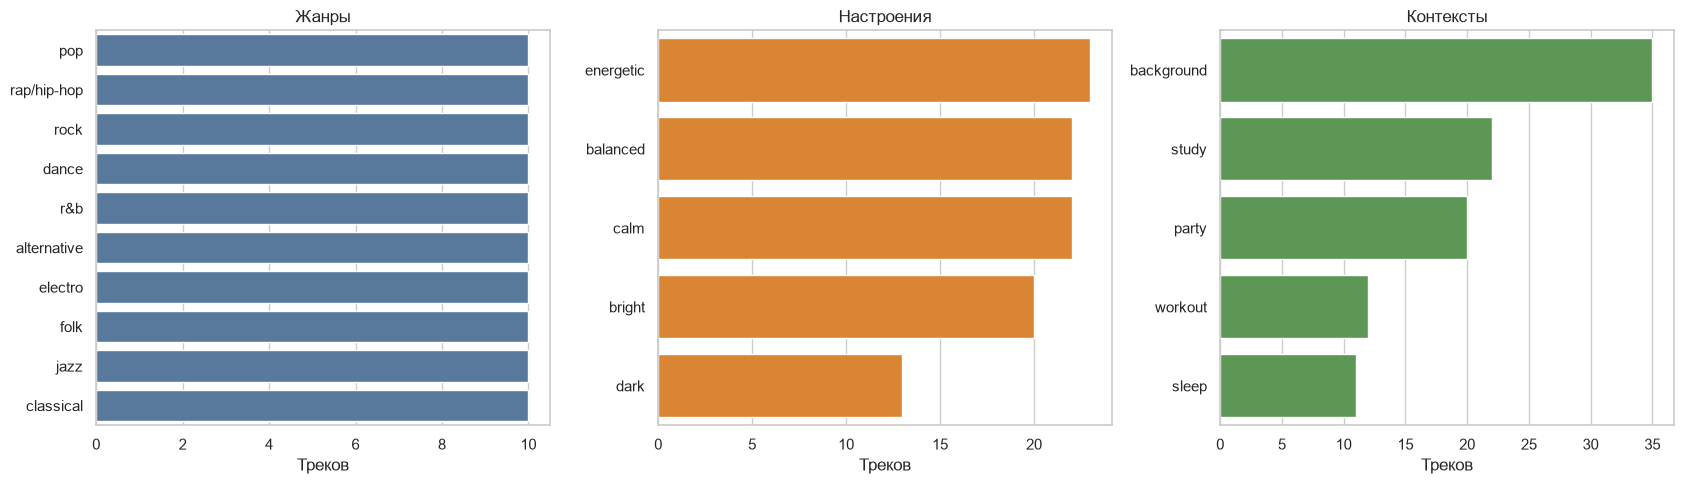

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.countplot(data=df, y='жанр', order=df['жанр'].value_counts().index, ax=axes[0], color='#4c78a8')
axes[0].set_title('Жанры')
axes[0].set_xlabel('Треков')
axes[0].set_ylabel('')

sns.countplot(data=df, y='настроение', order=df['настроение'].value_counts().index, ax=axes[1], color='#f58518')
axes[1].set_title('Настроения')
axes[1].set_xlabel('Треков')
axes[1].set_ylabel('')

sns.countplot(data=df, y='контекст', order=df['контекст'].value_counts().index, ax=axes[2], color='#54a24b')
axes[2].set_title('Контексты')
axes[2].set_xlabel('Треков')
axes[2].set_ylabel('')

plt.tight_layout()
plt.savefig(папка_графиков / 'distributions.png', dpi=160, bbox_inches='tight')
plt.show()

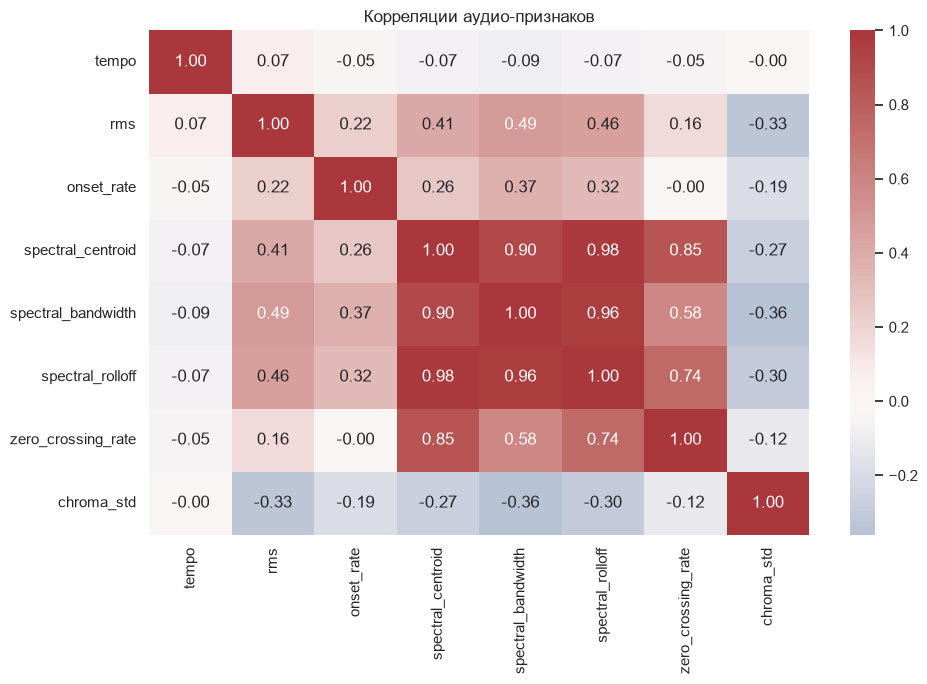

корреляция
spectral_centroid  spectral_rolloff      0.978470
spectral_bandwidth spectral_rolloff      0.957736
spectral_centroid  spectral_bandwidth    0.904550
                   zero_crossing_rate    0.846348
spectral_rolloff   zero_crossing_rate    0.738397

In [7]:
plt.figure(figsize=(10, 7))
корреляции = df[базовые_признаки].corr()
sns.heatmap(корреляции, cmap='vlag', center=0, annot=True, fmt='.2f')
plt.title('Корреляции аудио-признаков')
plt.tight_layout()
plt.savefig(папка_графиков / 'correlations.png', dpi=160, bbox_inches='tight')
plt.show()

пары = корреляции.where(np.triu(np.ones(корреляции.shape), k=1).astype(bool)).stack()
сильные_связи = пары.reindex(пары.abs().sort_values(ascending=False).index).head(5)
display(сильные_связи.rename('корреляция').to_frame())

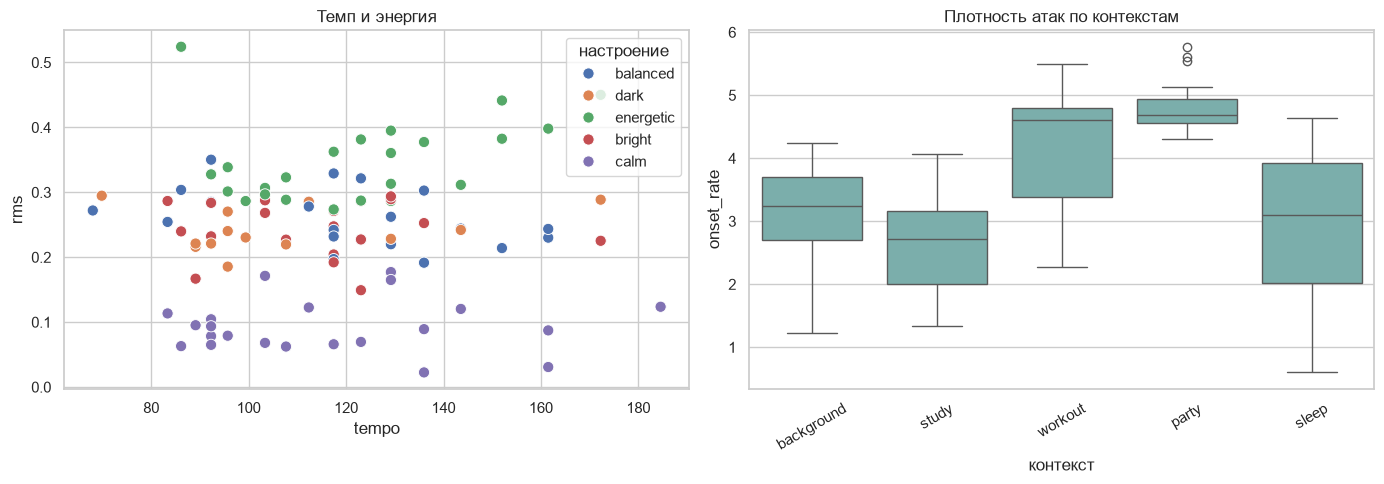

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x='tempo', y='rms', hue='настроение', ax=axes[0], s=65)
axes[0].set_title('Темп и энергия')

sns.boxplot(data=df, x='контекст', y='onset_rate', ax=axes[1], color='#72b7b2')
axes[1].tick_params(axis='x', rotation=30)
axes[1].set_title('Плотность атак по контекстам')

plt.tight_layout()
plt.savefig(папка_графиков / 'semantic_features.png', dpi=160, bbox_inches='tight')
plt.show()

### Наблюдения по EDA

Жанры сбалансированы специально: по 10 треков на класс. Семантические классы уже не обязаны быть равными, потому что они получены из звука. Корреляционная матрица помогает увидеть дублирующие признаки: спектральный центроид, bandwidth и rolloff обычно связаны между собой. Это важно для модели похожести — несколько почти одинаковых признаков могут слишком сильно повлиять на расстояние.

График `tempo × rms` показывает, что одного темпа мало для описания энергичности. Два трека с похожим BPM могут заметно различаться по средней энергии и плотности атак.

<a id="task-5"></a>
## Задание 5. Представление треков и похожесть

Для вектора трека использую восемь базовых признаков и 13 MFCC. Все столбцы стандартизируются, после чего похожесть считается косинусом между векторами. UMAP и t-SNE нужны только для двумерной визуализации; ближайшие соседи ищутся в исходном стандартизованном пространстве.

Качество оцениваю силуэтом жанров и семантических меток. Это не полноценная проверка рекомендаций: у нас нет оценок пользователей. Метрика лишь показывает, насколько заданные группы компактны в выбранном пространстве.

In [9]:
mfcc_столбцы = [f'mfcc_{номер}' for номер in range(1, 14)]
признаки_для_модели = базовые_признаки + mfcc_столбцы

масштабатор = StandardScaler()
матрица = масштабатор.fit_transform(df[признаки_для_модели])
матрица_похожести = cosine_similarity(матрица)

def найти_похожие(номер_трека, количество=5):
    neighbor_indices = np.argsort(матрица_похожести[номер_трека])[::-1][1:количество + 1]
    столбцы = ['название', 'исполнитель', 'жанр', 'настроение', 'контекст']
    результат = df.iloc[neighbor_indices][столбцы].copy()
    результат['схожесть'] = матрица_похожести[номер_трека, neighbor_indices]
    return результат

for номер_трека in [0, 25, 50]:
    трек = df.iloc[номер_трека]
    print(f"{трек['название']} — {трек['исполнитель']} ({трек['жанр']})")
    display(найти_похожие(номер_трека))

Nicole Kidman — ADÉLA (pop)


,название,исполнитель,жанр,настроение,контекст,схожесть
66,Spring,Mr. Polska,electro,energetic,workout,0.507687
63,L'Amour Toujours,Gigi D'Agostino,electro,calm,party,0.496565
15,1von1,Shindy,rap/hip-hop,energetic,background,0.455253
56,Earrings,Malcolm Todd,alternative,balanced,background,0.426178
9,Stop The Wedding!,Ashe,pop,balanced,background,0.399285


Wonderwall — Oasis (rock)


,название,исполнитель,жанр,настроение,контекст,схожесть
53,In the End,Linkin Park,alternative,bright,study,0.631127
57,back to friends,sombr,alternative,balanced,background,0.578880
24,Smells Like Teen Spirit,Nirvana,rock,bright,study,0.513232
44,Blinding Lights,The Weeknd,r&b,balanced,background,0.449662
55,The Emptiness Machine,Linkin Park,alternative,bright,background,0.441319


Self Aware — Temper City (alternative)


,название,исполнитель,жанр,настроение,контекст,схожесть
54,12 to 12,sombr,alternative,energetic,workout,0.690683
20,End of Beginning,Djo,rock,balanced,study,0.674257
43,MUTT,Leon Thomas,r&b,dark,background,0.671404
6,Housewife,Tate McRae,pop,energetic,workout,0.659039
30,Dracula (with JENNIE),Tame Impala,dance,energetic,background,0.657320


C:\Users\arsen\AppData\Local\Programs\Python\Python314\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


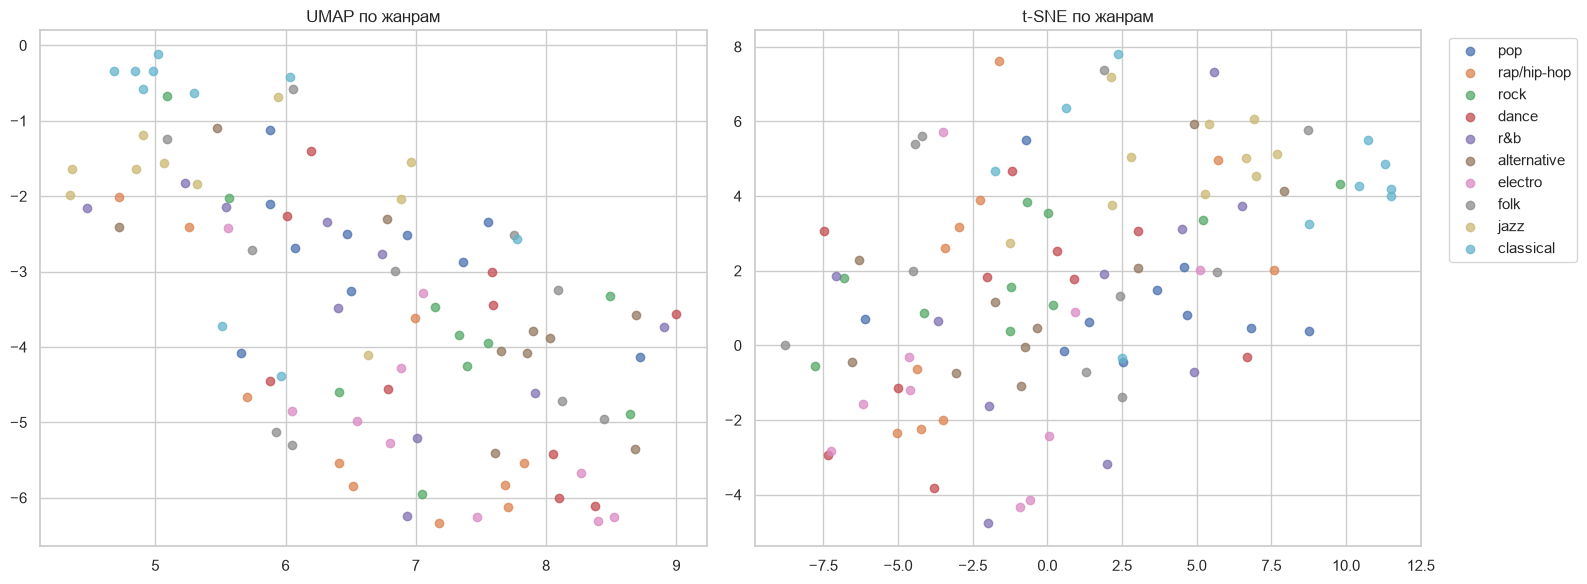

In [10]:
umap_модель = umap.UMAP(n_components=2, n_neighbors=12, min_dist=0.15, random_state=случайное_состояние)
umap_точки = umap_модель.fit_transform(матрица)

tsne_модель = TSNE(n_components=2, perplexity=20, init='pca', learning_rate='auto', random_state=случайное_состояние)
tsne_точки = tsne_модель.fit_transform(матрица)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for метка in df['жанр'].unique():
    маска = df['жанр'] == метка
    axes[0].scatter(umap_точки[маска, 0], umap_точки[маска, 1], label=метка, alpha=0.75)
    axes[1].scatter(tsne_точки[маска, 0], tsne_точки[маска, 1], label=метка, alpha=0.75)

axes[0].set_title('UMAP по жанрам')
axes[1].set_title('t-SNE по жанрам')
axes[1].legend(bbox_to_anchor=(1.03, 1), loc='upper left')
plt.tight_layout()
plt.savefig(папка_графиков / 'embeddings.png', dpi=160, bbox_inches='tight')
plt.show()

In [11]:
оценки = {
    'жанр': silhouette_score(матрица, df['жанр']),
    'настроение': silhouette_score(матрица, df['настроение']),
    'контекст': silhouette_score(матрица, df['контекст'])
}

pca = PCA().fit(матрица)
нагрузки = pd.Series(
    np.abs(pca.components_[0]),
    index=признаки_для_модели
).sort_values(ascending=False)

print('Silhouette score')
display(pd.Series(оценки).round(3).to_frame('значение'))
print('Наибольшие нагрузки первой компоненты PCA')
display(нагрузки.head(8).round(3).to_frame('нагрузка'))

np.save(папка_данных / 'track_embeddings.npy', матрица)
(папка_данных / 'experiment_metrics.json').write_text(
    json.dumps({ключ: float(значение) for ключ, значение in оценки.items()}, ensure_ascii=False, indent=2),
    encoding='utf-8'
)

Silhouette score


,значение
жанр,-0.074
настроение,-0.005
контекст,-0.031


Наибольшие нагрузки первой компоненты PCA


,нагрузка
spectral_bandwidth,0.340
spectral_rolloff,0.337
mfcc_2,0.324
spectral_centroid,0.319
mfcc_12,0.289
mfcc_1,0.282
mfcc_10,0.246
rms,0.237


109

### Выводы по эксперименту

Ближайшие соседи часто совпадают по общей плотности и тембру, но не всегда по жанру. Для content-based рекомендаций это скорее плюс: можно находить переходы между жанрами. При этом высокая косинусная схожесть означает близость только по выбранным признакам, а не гарантированное совпадение вкусов.

Наиболее полезными выглядят тембральные MFCC вместе с `rms`, `onset_rate` и `tempo`. Спектральные признаки помогают различать яркие и мягкие фрагменты, но часть из них коррелирует, поэтому в следующей версии я бы сократил набор или подобрал веса на пользовательских данных.

### Ограничения

- 100 треков мало для устойчивых выводов о жанрах
- выборка смещена в сторону текущих чартов Deezer
- анализируется только 30-секундный фрагмент, а не весь трек
- правила настроения и контекста являются эвристикой, а не ручной разметкой
- silhouette score не заменяет оценку рекомендаций пользователями
- ссылки на preview со временем могут измениться

### Что можно улучшить

Следующий разумный шаг — сравнить эти признаки с CLAP-эмбеддингами и собрать небольшую ручную оценку пар похожих треков. Тогда веса признаков и качество соседей можно проверять не только по жанровым меткам, но и по человеческим суждениям.